# DRL Assignment 1 — Group 3
## Reproducing *A Framework for Fair Evaluation of Variance-Aware Bandit Algorithms*

| Name | BITS ID |
|---|---|
| Suchintak Patnaik | 2025AG05930 |
| Yogamaya Dash | 2025AG05620 |
| Dialani Chitra BasantKumar | 2025AG05777 |
| Bhatt Dhruv Anil | 2025AG05557 |

**Paper:** Wolf (2025), arXiv:2510.27001 — https://arxiv.org/abs/2510.27001
**Author's code (Bandit Playground):** https://github.com/eelisee/bandit_playground/tree/v1.0-SKILL2025

**What this notebook does** (all code written by Group 3, from the algorithm definitions in the original papers):

| § | Content | Supports slides |
|---|---|---|
| 1 | Setup and experiment configuration | 9–10 |
| 2 | From-scratch implementations of all 8 algorithms + the fair-evaluation harness | 6–8, 11 |
| 3 | *Why* variance-awareness helps — exploration-bonus demo | 8 |
| 4 | Fairness controls in action — arm ordering and common random numbers | 11 |
| 5 | Main experiment: the author's published CSVs (source of every number on our slides), our independent reproduction, and our fair version | 12–16, 22 |
| 6 | Tuning sensitivity: ETC *m* sweep and ε-Greedy ε sweep | 20 |
| 7 | Extension: decoupling mean and variance with Beta rewards | 21, 24 |
| 8 | Summary and references | 25–27 |

**Run it:** `pip install numpy pandas matplotlib numba` then *Run All*. Works on Google Colab as-is.
With `numba` the full paper setting (10⁶ pulls × 100 runs × both arm orders) takes a few minutes on a laptop;
without `numba` the notebook automatically switches to a smaller "quick" setting.

## 1. Setup and configuration

Experimental setting from the paper (slide 9–10):
* stochastic 2-armed bandit, independent **Bernoulli** rewards, stationary;
* horizon **T = 1,000,000** pulls, **100 repetitions**, results averaged;
* three scenarios that vary the reward gap Δ and the reward variance p(1−p).

In [1]:
import os, math, time, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from numba import njit, prange
    HAVE_NUMBA = True
except ImportError:                       # pure-Python fallback (slow, so we shrink the experiment)
    HAVE_NUMBA = False
    def njit(*args, **kwargs):
        if args and callable(args[0]):
            return args[0]
        return lambda f: f
    prange = range

os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("numba available:", HAVE_NUMBA)

numba available: True


In [2]:
MODE  = "paper" if HAVE_NUMBA else "quick"     # set to "quick" for a fast demo run
T     = 1_000_000 if MODE == "paper" else 20_000
RUNS  = 100       if MODE == "paper" else 5    # repetitions *per arm ordering*
SEED  = 2025

SCENARIOS = {                                  # (p_arm1, p_arm2)
    "A": (0.800, 0.900),    # baseline: large gap
    "B": (0.895, 0.900),    # micro-gap, lower variance
    "C": (0.890, 0.895),    # micro-gap, higher variance
}

rows = []
for s, (p1, p2) in SCENARIOS.items():
    rows.append({"scenario": s, "p1": p1, "p2": p2, "gap": round(abs(p2 - p1), 3),
                 "var1 = p1(1-p1)": round(p1 * (1 - p1), 4), "var2 = p2(1-p2)": round(p2 * (1 - p2), 4)})
print(f"MODE={MODE}  T={T:,}  runs per ordering={RUNS}")
pd.DataFrame(rows)

MODE=paper  T=1,000,000  runs per ordering=100


,scenario,p1,p2,gap,var1 = p1(1-p1),var2 = p2(1-p2)
0,A,0.800,0.900,0.100,0.1600,0.090
1,B,0.895,0.900,0.005,0.0940,0.090
2,C,0.890,0.895,0.005,0.0979,0.094


Note the last two columns: for a 0/1 reward the variance is **fixed by the win rate**. B and C differ in
variance by only ≈ 4 %, and the gap cannot be held fixed while the variance changes. This is the design
issue on slide 21, and it motivates the extension in §7.

## 2. Algorithms and fair-evaluation harness

All index formulas are taken from the original papers. Notation: $\hat\mu_a$ = empirical mean, $\hat V_a$ = empirical
variance, $n_a$ = number of pulls of arm $a$, $t$ = current time step, $K$ = number of arms.

| Algorithm | Arm chosen at step t | Source |
|---|---|---|
| ETC(m) | pull each arm m times, then commit to the best empirical mean | Lattimore & Szepesvári (2020) |
| ε-Greedy(ε) | random arm w.p. ε, otherwise $\arg\max\hat\mu_a$ | Sutton & Barto (2018) |
| UCB1 | $\hat\mu_a + \sqrt{2\ln t / n_a}$ | Auer et al. (2002) |
| UCB-Tuned | $\hat\mu_a + \sqrt{\tfrac{\ln t}{n_a}\min\left(\tfrac14,\ \hat V_a + \sqrt{2\ln t/n_a}\right)}$ | Auer et al. (2002) |
| UCB-V | $\hat\mu_a + \sqrt{2\hat V_a \mathcal E_t / n_a} + 3\mathcal E_t/n_a,\ \ \mathcal E_t = \theta\ln t,\ \theta=1$ | Audibert et al. (2009) |
| PAC-UCB | as UCB-V but with $L = \max(\ln(K n_a^{q}/\beta),\,2)$, $q=1.3,\ \beta=0.05$ — **no dependence on t** | Audibert et al. (2009) |
| UCB-Improved | phases: pull active arms $n_m$ times, eliminate, halve $\tilde\Delta$ | Auer & Ortner (2010) |
| EUCBV | $\hat\mu_a + \sqrt{\rho(\hat V_a+2)\ln(\psi T\varepsilon_m)/(4n_a)}$ + arm elimination, $\rho=\tfrac12,\ \psi=T/K^2$ | Mukherjee et al. (2018) |

**Why variance helps (justification).** UCB1's bonus comes from Hoeffding's inequality, which assumes the worst-case
variance ¼ for a [0,1] reward. UCB-Tuned and UCB-V use a *Bernstein*-type bound instead, where the leading term scales with
$\sqrt{\hat V_a}$. When an arm's rewards are consistent ($\hat V_a$ small) the bonus shrinks, so fewer pulls are spent exploring it.

**Fairness controls built into the harness** (paper §3, our slide 11):
1. *Same initialisation*: every algorithm first pulls each arm once.
2. *Same randomness*: a **reward stack** `X[k, j]` (the reward of the j-th pull of arm k) is generated from the run's seed
   **before** the algorithm starts, so every algorithm sees exactly the same rewards.
3. *One pull per time step*: UCB-Improved is written so that it pulls one arm per step, as in the paper.
4. *Both arm orderings*: every experiment is run with the arms in both orders, so deterministic tie-breaking
   (lowest index wins) cannot favour one arm.
Constants (θ, c, b, q, β, ρ) are the ones in the author's `src/config.py`, so our numbers can be compared with hers.

5. *Regret* is the pseudo-regret $R_T = \sum_t (\mu^* - \mu_{a_t})$, the same definition the paper uses
   (e.g. ETC with m = 100 in Scenario A gives 100 × 0.1 ≈ 10.1).

In [3]:
# algorithm ids
ETC, GREEDY, UCB1, UCB_TUNED, UCB_V, EUCBV, PAC_UCB, UCB_IMPROVED = range(8)
# variants that copy the author's implementation choices (see section 2.1)
ETC_AUTHOR, GREEDY_AUTHOR, UCB_IMPROVED_AUTHOR = 8, 9, 10

@njit
def ucb1_index(mean, n, t):
    return mean + math.sqrt(2.0 * math.log(t) / n)

@njit
def ucb_tuned_index(mean, var, n, t):
    v = var + math.sqrt(2.0 * math.log(t) / n)
    return mean + math.sqrt(math.log(t) / n * min(0.25, v))

@njit
def ucb_v_index(mean, var, n, t, theta=1.0, c=1.0, b=1.0):
    e = theta * math.log(t)
    return mean + math.sqrt(2.0 * var * e / n) + 3.0 * c * b * e / n

@njit
def pac_ucb_index(mean, var, n, K, q=1.3, beta=0.05):
    L = max(math.log(K * n ** q / beta), 2.0)       # depends on n only, not on t
    return mean + math.sqrt(2.0 * var * L / n) + 3.0 * L / n

@njit
def eucbv_radius(var, n, rho, psi, T, eps):
    return math.sqrt(rho * (var + 2.0) * math.log(psi * T * eps) / (4.0 * n))

@njit
def argmax_active(values, active):
    best, best_v = -1, -np.inf
    for i in range(values.shape[0]):
        if active[i] and values[i] > best_v:        # strict '>' -> ties go to the lowest index
            best, best_v = i, values[i]
    return best

@njit
def argmin_count_active(counts, active):
    best, best_c = -1, 1 << 62
    for i in range(counts.shape[0]):
        if active[i] and counts[i] < best_c:
            best, best_c = i, counts[i]
    return best

In [4]:
@njit
def simulate(algo, param, p, alpha, beta_, T, seed, ckpts):
    # One run of one algorithm. Returns the regret curve at the checkpoints, total reward, pulls per arm.
    np.random.seed(seed)
    K = p.shape[0]

    # Fairness control 2: reward stack, generated before the algorithm acts.
    X = np.empty((K, T))
    for k in range(K):
        for j in range(T):
            if alpha[k] > 0.0:                                    # Beta rewards (extension, section 7)
                X[k, j] = np.random.beta(alpha[k], beta_[k])
            else:                                                 # Bernoulli rewards (paper)
                X[k, j] = 1.0 if np.random.random() < p[k] else 0.0

    counts = np.zeros(K, np.int64)
    sums = np.zeros(K)
    sumsq = np.zeros(K)
    active = np.ones(K, np.bool_)
    means = np.zeros(K)
    idx = np.zeros(K)
    mu_star = p.max()
    regret, total = 0.0, 0.0
    curve = np.zeros(ckpts.shape[0])
    ci = 0

    committed = -1                                                # ETC
    M = int(math.floor(0.5 * math.log2(T / math.e)))              # UCB-Improved / EUCBV number of phases
    d = 1.0                                                       # UCB-Improved: current gap guess
    phase = 0
    n_m = int(math.ceil(2.0 * math.log(T * d * d) / (d * d)))
    rho, psi, eps = 0.5, T / (K * K), 1.0                         # EUCBV
    n_e = int(math.ceil(math.log(psi * T * eps * eps) / (2.0 * eps)))
    N_e = K * n_e
    m_e = 0
    done = np.zeros(K, np.bool_)                                  # UCB-Improved (author): pulled in this phase

    for t in range(1, T + 1):
        # ---------------- choose an arm ----------------
        a = -1
        for k in range(K):
            means[k] = sums[k] / counts[k] if counts[k] > 0 else 0.0
        if algo != GREEDY_AUTHOR and algo != UCB_IMPROVED_AUTHOR:
            for k in range(K):                                    # fairness control 1: pull each arm once
                if counts[k] == 0:
                    a = k
                    break
        if algo == ETC_AUTHOR:                                    # author: round robin, then argmax of the
            if t <= param * K:                                    # running means at every step (no lock-in)
                a = (t - 1) % K
            else:
                a = argmax_active(means, active)
        elif algo == GREEDY_AUTHOR:                               # author: Q starts at 0, no initial pulls
            if np.random.random() < param:
                a = np.random.randint(0, K)
            else:
                a = argmax_active(means, active)
        elif algo == UCB_IMPROVED_AUTHOR:                         # author: ONE pull per arm per phase,
            while a < 0:                                          # then eliminate as if n_m pulls were made
                if phase >= M:
                    a = argmax_active(means, active)
                    break
                for k in range(K):
                    if active[k] and not done[k]:
                        a = k
                        done[k] = True
                        break
                if a < 0:
                    n_req = math.ceil(2.0 * math.log(T * d * d) / (d * d))
                    w = math.sqrt(math.log(T * d * d) / (2.0 * n_req))
                    best_lcb = -np.inf
                    for j in range(K):
                        if active[j] and means[j] - w > best_lcb:
                            best_lcb = means[j] - w
                    for j in range(K):
                        if active[j] and means[j] + w < best_lcb:
                            active[j] = False
                    d /= 2.0
                    phase += 1
                    done[:] = False
        elif a < 0:
            if algo == ETC:
                if committed < 0:
                    k = argmin_count_active(counts, active)
                    if counts[k] < param:
                        a = k                                     # still exploring (round robin)
                    else:
                        committed = argmax_active(means, active)  # commit for the rest of the game
                if committed >= 0:
                    a = committed
            elif algo == GREEDY:
                if np.random.random() < param:
                    a = np.random.randint(0, K)
                else:
                    a = argmax_active(means, active)
            elif algo == UCB_IMPROVED:
                while a < 0:
                    n_act = 0
                    for k in range(K):
                        if active[k]:
                            n_act += 1
                    if n_act == 1 or phase > M:
                        a = argmax_active(means, active)
                        break
                    k = argmin_count_active(counts, active)
                    if counts[k] < n_m:
                        a = k                                     # fairness control 3: one pull per step
                    else:                                         # phase finished: eliminate, halve d
                        w = math.sqrt(math.log(T * d * d) / (2.0 * n_m))
                        best_lcb = -np.inf
                        for j in range(K):
                            if active[j] and means[j] - w > best_lcb:
                                best_lcb = means[j] - w
                        for j in range(K):
                            if active[j] and means[j] + w < best_lcb:
                                active[j] = False
                        d /= 2.0
                        phase += 1
                        n_m = int(math.ceil(2.0 * math.log(T * d * d) / (d * d)))
            else:
                for k in range(K):
                    n = counts[k]
                    var = max(sumsq[k] / n - means[k] * means[k], 0.0)
                    if algo == UCB1:
                        idx[k] = ucb1_index(means[k], n, t)
                    elif algo == UCB_TUNED:
                        idx[k] = ucb_tuned_index(means[k], var, n, t)
                    elif algo == UCB_V:
                        idx[k] = ucb_v_index(means[k], var, n, t)
                    elif algo == PAC_UCB:
                        idx[k] = pac_ucb_index(means[k], var, n, K)
                    else:                                         # EUCBV
                        idx[k] = means[k] + eucbv_radius(var, n, rho, psi, T, eps)
                a = argmax_active(idx, active)

        # ---------------- observe reward ----------------
        x = X[a, counts[a]]
        counts[a] += 1
        sums[a] += x
        sumsq[a] += x * x
        total += x
        regret += mu_star - p[a]
        if ci < ckpts.shape[0] and t == ckpts[ci]:
            curve[ci] = regret
            ci += 1

        # ---------------- EUCBV: elimination and epoch reset ----------------
        if algo == EUCBV and t >= K:
            best_lcb = -np.inf
            for k in range(K):
                if active[k]:
                    m_k = sums[k] / counts[k]
                    r_k = eucbv_radius(max(sumsq[k] / counts[k] - m_k * m_k, 0.0), counts[k], rho, psi, T, eps)
                    idx[k] = r_k
                    if m_k - r_k > best_lcb:
                        best_lcb = m_k - r_k
            for k in range(K):
                if active[k] and sums[k] / counts[k] + idx[k] < best_lcb:
                    active[k] = False
            if t >= N_e and m_e <= M:
                eps /= 2.0
                n_e = int(math.ceil(math.log(psi * T * eps * eps) / (2.0 * eps)))
                n_act = 0
                for k in range(K):
                    if active[k]:
                        n_act += 1
                N_e = t + n_act * n_e
                m_e += 1

    return curve, total, counts


@njit(parallel=True)
def run_batch(algo, param, p, alpha, beta_, T, seeds, ckpts):
    R = seeds.shape[0]
    curves = np.zeros((R, ckpts.shape[0]))
    rewards = np.zeros(R)
    pulls = np.zeros((R, p.shape[0]))
    for r in prange(R):
        c, tot, cnt = simulate(algo, param, p, alpha, beta_, T, seeds[r], ckpts)
        curves[r, :] = c
        rewards[r] = tot
        for k in range(p.shape[0]):
            pulls[r, k] = cnt[k]
    return curves, rewards, pulls

### 2.1 Three algorithms where the author's code differs from the textbook

We read the author's code at tag `v1.0-SKILL2025` (`src/algorithms/*.py`). Three implementations differ from the original
algorithm definitions, and these differences explain the paper numbers that our textbook versions do not reproduce. We
implemented each one as an extra *author variant*, so the simulator can produce both sets of numbers:

| Algorithm | Textbook (our `ETC`, `GREEDY`, `UCB_IMPROVED`) | Author's code (our `*_AUTHOR` variants) | Effect |
|---|---|---|---|
| ETC (`ETC.py`) | after exploring, **commit** to one arm for the rest of the game | after exploring, take `argmax` of the running means **at every step**, so a wrong choice can be undone | ETC looks much better in the paper (e.g. 150.66 instead of ≈ 690 in Scenario B) |
| ε-Greedy (`Greedy.py`) | pull every arm once first | Q starts at 0 with no initial pulls, so `argmax` picks arm 1 first; exploration uses **unseeded** `np.random` | results depend on arm order (Scenario C, ε = 0.005: 1762.59 in one order, 216.31 in the other) and cannot be re-run exactly |
| UCB-Improved (`UCB_Improved.py`) | pull each active arm $n_m$ times per phase, then eliminate | pulls each arm **once** per phase, then eliminates using the width for $n_m$ pulls | elimination becomes almost a coin flip: each run ends with regret ≈ 0 or ≈ Δ·T, which explains 32,500 in Scenario A (§5.4) |

In [5]:
def checkpoints(T, n=60):
    return np.unique(np.geomspace(1, T, n).astype(np.int64))

def evaluate(algo, param, probs, T=T, runs=RUNS, seed=SEED, variances=None, orders="both"):
    # Runs one algorithm on one environment with common random numbers.
    # orders='both' -> fairness control 4: every arm permutation, `runs` repetitions each.
    probs = np.asarray(probs, float)
    K = len(probs)
    if variances is None:                                    # Bernoulli
        alpha, beta_ = np.zeros(K), np.zeros(K)
    else:                                                    # Beta with given mean and variance
        v = np.asarray(variances, float)
        common = probs * (1 - probs) / v - 1.0
        alpha, beta_ = probs * common, (1 - probs) * common
    ck = checkpoints(T)
    perms = list(itertools.permutations(range(K))) if orders == "both" else [tuple(range(K))]
    seeds = seed + np.arange(runs, dtype=np.int64)           # same seeds for every algorithm
    curves, rewards, subopt = [], [], []
    for perm in perms:
        perm = list(perm)
        c, rw, pl = run_batch(algo, float(param), probs[perm], alpha[perm], beta_[perm], T, seeds, ck)
        best = int(np.argmax(probs[perm]))
        curves.append(c)
        rewards.append(rw)
        subopt.append((pl.sum(1) - pl[:, best]) / T)
    curves = np.vstack(curves)
    return {"ckpts": ck, "curves": curves, "regret": curves[:, -1],
            "reward": np.concatenate(rewards), "subopt": np.concatenate(subopt)}

# compile once and sanity-check determinism (same seed -> identical result)
t0 = time.time()
r1 = evaluate(UCB_TUNED, 0, SCENARIOS["C"], T=10_000, runs=4)
r2 = evaluate(UCB_TUNED, 0, SCENARIOS["C"], T=10_000, runs=4)
print(f"compiled in {time.time() - t0:.1f}s | deterministic: {np.array_equal(r1['regret'], r2['regret'])}")

compiled in 2.6s | deterministic: True


In [6]:
# The 16 algorithm settings evaluated in the paper.
# ETC m-values and the eps = 0.005 / 0.05 / 0.5 Greedy settings appear in the paper's figures;
# eps = 0.01 and 0.1 are our assumption for the remaining two Greedy settings.
ALGOS = (
    [(f"ETC (m={m:,})", ETC, m, "Standard") for m in (10, 100, 1_000, 10_000, 100_000)]
  + [(f"Greedy (ε={e})", GREEDY, e, "Standard") for e in (0.005, 0.01, 0.05, 0.1, 0.5)]
  + [("UCB", UCB1, 0, "Standard"),
     ("UCB-Tuned", UCB_TUNED, 0, "Variance-aware"),
     ("UCB-V", UCB_V, 0, "Variance-aware"),
     ("EUCBV", EUCBV, 0, "Variance-aware"),
     ("PAC-UCB", PAC_UCB, 0, "Non-variance-aware"),
     ("UCB-Improved", UCB_IMPROVED, 0, "Non-variance-aware")]
)
CAT_COLORS = {"Standard": "#1f77b4", "Variance-aware": "#2ca02c", "Non-variance-aware": "#ff7f0e"}

# Cumulative regret shown on our slides 13-16 and 20 (= the paper's figures). Section 5.0 checks every value
# against the author's published CSV files.
PAPER = {
 "A": {"ETC (m=100)": 10.10, "ETC (m=1,000)": 100.00, "ETC (m=10,000)": 1000.00, "UCB": 238.17,
       "Greedy (ε=0.005)": 422.99, "Greedy (ε=0.5)": 25002.20, "UCB-Tuned": 30.67, "EUCBV": 47.73,
       "UCB-V": 109.93, "PAC-UCB": 99.50, "UCB-Improved": 32500.11},
 "B": {"ETC (m=10,000)": 150.66, "UCB-Tuned": 212.21, "UCB-V": 346.58, "Greedy (ε=0.05)": 361.97,
       "PAC-UCB": 395.89, "EUCBV": 461.36, "UCB": 1127.17, "Greedy (ε=0.5)": 1264.52,
       "Greedy (ε=0.005)": 1428.70, "UCB-Improved": 2525.00},
 "C": {"ETC (m=10,000)": 170.53, "Greedy (ε=0.05)": 301.55, "ETC (m=100,000)": 500.00, "UCB": 1172.57,
       "Greedy (ε=0.5)": 1269.05, "Greedy (ε=0.005)": 1762.59, "ETC (m=10)": 2150.00, "UCB-Tuned": 226.09,
       "UCB-V": 367.65, "EUCBV": 476.31, "PAC-UCB": 417.34, "UCB-Improved": 2450.00},
}

## 3. Why variance-awareness helps — the exploration bonus

Below we plot the exploration bonus (index − mean) at time t = 10,000 for a **noisy** arm (p = 0.5, variance 0.25)
and a **consistent** arm (p = 0.95, variance 0.0475). UCB1 gives both arms the same bonus because it ignores
variance. UCB-Tuned and UCB-V give the consistent arm a smaller bonus, so it stops being re-explored sooner.
(At very small $n_a$ UCB-V's bonus is *larger* than UCB1's because of its $3\mathcal E_t/n_a$ correction term. That term
fades as $1/n_a$, and the variance term $\sqrt{\hat V_a}$ takes over.)

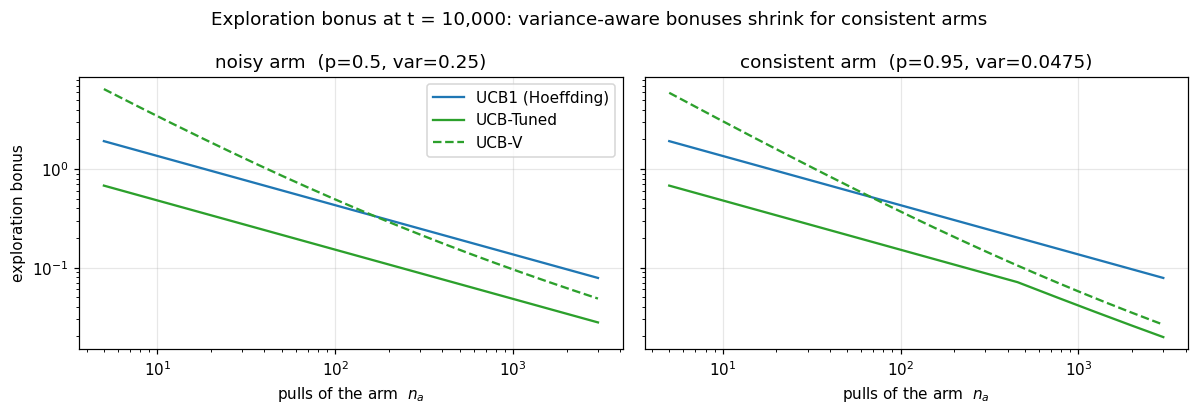

p=0.5   n=1000:  UCB1=0.1357  UCB-Tuned=0.0480  UCB-V=0.0955
p=0.95  n=1000:  UCB1=0.1357  UCB-Tuned=0.0411  UCB-V=0.0572


In [7]:
t_fix = 10_000
n = np.arange(5, 3001)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a_, (p_, title) in zip(ax, [(0.5, "noisy arm  (p=0.5, var=0.25)"), (0.95, "consistent arm  (p=0.95, var=0.0475)")]):
    v = p_ * (1 - p_)
    a_.plot(n, [ucb1_index(0, k, t_fix) for k in n], label="UCB1 (Hoeffding)", color="#1f77b4")
    a_.plot(n, [ucb_tuned_index(0, v, k, t_fix) for k in n], label="UCB-Tuned", color="#2ca02c")
    a_.plot(n, [ucb_v_index(0, v, k, t_fix) for k in n], label="UCB-V", color="#2ca02c", ls="--")
    a_.set(xscale="log", yscale="log", title=title, xlabel="pulls of the arm  $n_a$")
ax[0].set_ylabel("exploration bonus")
ax[0].legend()
plt.suptitle(f"Exploration bonus at t = {t_fix:,}: variance-aware bonuses shrink for consistent arms")
plt.tight_layout()
plt.savefig("figures/bonus_shrink.png", bbox_inches="tight")
plt.show()

k = 1000
for p_ in (0.5, 0.95):
    v = p_ * (1 - p_)
    print(f"p={p_:<5} n={k}:  UCB1={ucb1_index(0, k, t_fix):.4f}  UCB-Tuned={ucb_tuned_index(0, v, k, t_fix):.4f}"
          f"  UCB-V={ucb_v_index(0, v, k, t_fix):.4f}")

## 4. Fairness controls in action

**Arm ordering.** With deterministic tie-breaking (lowest index wins), ETC with m = 10 in Scenario C often sees a
*tie* after exploration (both arms win about 9 of 10 pulls), and the tie goes to whichever arm is listed first. The
result then depends on the order the arms are listed in, which says nothing about the algorithm itself. Averaging over both
orders removes this bias, which is why the paper evaluates all permutations.

In [8]:
pC = SCENARIOS["C"]
fwd = evaluate(ETC, 10, pC, orders="one")                      # best arm listed second
rev = evaluate(ETC, 10, pC[::-1], orders="one")                # best arm listed first
both = evaluate(ETC, 10, pC)
pd.DataFrame({
    "arm order": [f"{pC} (best arm 2nd)", f"{pC[::-1]} (best arm 1st)", "both orders (fair)"],
    "mean regret": [fwd["regret"].mean(), rev["regret"].mean(), both["regret"].mean()],
    "paper": ["", "", PAPER["C"]["ETC (m=10)"]],
}).round(2)

,arm order,mean regret,paper
0,"(0.89, 0.895) (best arm 2nd)",2899.99,
1,"(0.895, 0.89) (best arm 1st)",2000.01,
2,both orders (fair),2450.00,2150.0


**Common random numbers.** Every algorithm receives the same reward stack for a given seed. Here are the first
10 rewards from arm 1 for seed 2025. The same values are fed to every algorithm, so differences in regret come from the
algorithms and not from luck.

In [9]:
@njit
def peek_stack(p, seed, n):
    np.random.seed(seed)
    X = np.empty((p.shape[0], n))
    for k in range(p.shape[0]):
        for j in range(n):
            X[k, j] = 1.0 if np.random.random() < p[k] else 0.0
    return X

print("arm 1, first 10 pulls:", peek_stack(np.array(pC), SEED, T)[0, :10].astype(int))

arm 1, first 10 pulls: [1 1 0 1 1 1 1 1 0 1]


## 5. Main experiment — Scenarios A, B, C

### 5.0 Source of the numbers on our slides: the author's published results
The author's repository includes the CSV result files behind the paper (`data/<algorithm>/<params>/average_results_<p1>_<p2>.csv`,
100 runs, T = 10⁶, global seed 42). We download them and check **every number on our slides** against them.
The file suffix gives the arm order: `800_900` means arm 1 = 0.80 and arm 2 = 0.90.

In [10]:
import urllib.request

AUTHOR_URL = "https://raw.githubusercontent.com/eelisee/bandit_playground/v1.0-SKILL2025/data"
AUTHOR_DIR = {**{f"ETC (m={m:,})": f"ETC/exploration_rounds_{m}" for m in (10, 100, 1_000, 10_000, 100_000)},
              **{f"Greedy (ε={e})": "Greedy/epsilon_" + str(e).replace(".", "_") for e in (0.005, 0.01, 0.05, 0.1, 0.5)},
              "UCB": "UCB/default", "UCB-Tuned": "UCB-Tuned/default", "UCB-V": "UCB-V/theta_1_c_1_b_1",
              "EUCBV": "EUCBV/rho_0_5", "PAC-UCB": "PAC-UCB/c_1_b_1_q_1_3_beta_0_05", "UCB-Improved": "UCB-Improved/delta_1"}
FILE_TAG = {"A": ("800_900", "900_800"), "B": ("895_900", "900_895"), "C": ("890_895", "895_890")}

def author_csv(label, fname):
    # download once into author_data/, then read from disk
    local = os.path.join("author_data", AUTHOR_DIR[label], fname)
    if not os.path.exists(local):
        os.makedirs(os.path.dirname(local), exist_ok=True)
        urllib.request.urlretrieve(f"{AUTHOR_URL}/{AUTHOR_DIR[label]}/{fname}", local)
    return pd.read_csv(local)

rows = []
for s in SCENARIOS:
    fwd, rev = FILE_TAG[s]
    for label, *_ in ALGOS:
        rows.append({"scenario": s, "algorithm": label,
                     "author_fwd": author_csv(label, f"average_results_{fwd}.csv")["Average Regret"].iloc[-1],
                     "author_rev": author_csv(label, f"average_results_{rev}.csv")["Average Regret"].iloc[-1],
                     "slide_value": PAPER[s].get(label, np.nan)})
author = pd.DataFrame(rows)
author.to_csv("results/author_published_results.csv", index=False)

on_slides = author.dropna(subset=["slide_value"])
match = np.isclose(on_slides.slide_value, on_slides.author_fwd, atol=0.015)
print(f"{match.sum()} of {len(on_slides)} numbers on our slides equal the author's CSV (arm order {', '.join(t[0] for t in FILE_TAG.values())})")
author.round(2)

33 of 33 numbers on our slides equal the author's CSV (arm order 800_900, 895_900, 890_895)


,scenario,algorithm,author_fwd,author_rev,slide_value
0,A,ETC (m=10),7004.08,11001.35,NaN
1,A,ETC (m=100),10.10,10.06,10.10
2,A,"ETC (m=1,000)",100.00,100.00,100.00
3,A,"ETC (m=10,000)",1000.00,1000.00,1000.00
4,A,"ETC (m=100,000)",10000.00,10000.00,NaN
5,A,Greedy (ε=0.005),422.99,256.00,422.99
6,A,Greedy (ε=0.01),588.01,499.90,NaN
7,A,Greedy (ε=0.05),2518.47,2502.90,NaN
8,A,Greedy (ε=0.1),5008.48,5002.57,NaN
9,A,Greedy (ε=0.5),25002.20,25003.17,25002.20


**Result:** every number on our slides comes from the author's CSV for **one arm order only** (worse arm listed first).
The paper does not report the reverse order, even though its fairness protocol says all permutations are run. For ε-Greedy
with small ε the two orders differ by up to 8× (column `author_rev`).

### 5.1 Our independent runs
We run two experiments with our own code:
* **Reproduction**: the paper's protocol (100 runs, worse arm listed first) using the author's implementation choices
  (`*_AUTHOR` variants from §2.1). These numbers should be close to the slides, apart from random-seed noise.
* **Fair version**: textbook algorithms, both arm orders, 2 × `RUNS` runs. This is what we consider the correct comparison.

Everything is logged to `results/main_results.csv` and `results/per_run_regret.csv`.

In [11]:
AUTHOR_VARIANT = {ETC: ETC_AUTHOR, GREEDY: GREEDY_AUTHOR, UCB_IMPROVED: UCB_IMPROVED_AUTHOR}
RESULTS, REPRO, rows, per_run = {}, {}, [], []
t_start = time.time()
for s, probs in SCENARIOS.items():
    for label, algo, param, cat in ALGOS:
        t0 = time.time()
        rep_ = evaluate(AUTHOR_VARIANT.get(algo, algo), param, probs, runs=RUNS, orders="one")   # reproduction
        REPRO[(s, label)] = rep_
        res = evaluate(algo, param, probs)                                                       # fair version
        RESULTS[(s, label)] = res
        reg = res["regret"]
        rows.append({"scenario": s, "algorithm": label, "category": cat,
                     "slide_value": PAPER[s].get(label, np.nan),
                     "author_csv": author.loc[(author.scenario == s) & (author.algorithm == label), "author_fwd"].item(),
                     "reproduction": rep_["regret"].mean(),
                     "mean_regret": reg.mean(), "std_regret": reg.std(ddof=1),
                     "median_regret": np.median(reg), "VaR95_regret": np.quantile(reg, 0.95),
                     "mean_reward": res["reward"].mean(), "subopt_ratio": res["subopt"].mean(),
                     })
        per_run += [{"scenario": s, "algorithm": label, "run": i, "regret": r} for i, r in enumerate(reg)]
        print(f"{s}  {label:<18} reproduction={rep_['regret'].mean():>10.2f}   fair={reg.mean():>10.2f}   ({time.time() - t0:5.1f}s)")
print(f"total {time.time() - t_start:.0f}s")

df = pd.DataFrame(rows)
df.to_csv("results/main_results.csv", index=False)
pd.DataFrame(per_run).to_csv("results/per_run_regret.csv", index=False)

A  ETC (m=10)         reproduction=   6001.73   fair=  29000.42   (  0.4s)


A  ETC (m=100)        reproduction=     10.33   fair=   2509.50   (  0.4s)


A  ETC (m=1,000)      reproduction=    100.00   fair=    100.00   (  0.4s)


A  ETC (m=10,000)     reproduction=   1000.00   fair=   1000.00   (  0.4s)


A  ETC (m=100,000)    reproduction=  10000.00   fair=  10000.00   (  0.4s)


...

C  UCB-Tuned          reproduction=    217.06   fair=    231.02   (  0.9s)


C  UCB-V              reproduction=    344.45   fair=    363.12   (  0.9s)


C  EUCBV              reproduction=    444.03   fair=    468.67   (  1.2s)


C  PAC-UCB            reproduction=    406.80   fair=    430.02   (  2.2s)


C  UCB-Improved       reproduction=   2000.01   fair=   1803.40   (  0.6s)
total 36s


### 5.2 Slides vs author's CSV vs our runs
* `slide_value` = number on our slide; `author_csv` = the author's file it comes from.
* `reproduction` = our code with the author's implementation choices (should be close to `author_csv`).
* `mean_regret` = our fair version (textbook algorithms, both arm orders).
* `repro/author` close to 1 means we reproduced the published number. ρ = Spearman rank correlation between the
  reproduction and the author's results across all 16 settings.

In [12]:
for s in SCENARIOS:
    sub = df[df.scenario == s].sort_values("author_csv")
    rho = sub["reproduction"].rank().corr(sub["author_csv"].rank())
    print(f"\nScenario {s}  {SCENARIOS[s]}   Spearman rank correlation, reproduction vs author: {rho:.2f}")
    show = sub[["algorithm", "slide_value", "author_csv", "reproduction", "mean_regret", "median_regret", "VaR95_regret", "subopt_ratio"]].copy()
    show["repro/author"] = show.reproduction / show.author_csv
    display(show.round(3).reset_index(drop=True))


Scenario A  (0.8, 0.9)   Spearman rank correlation, reproduction vs author: 1.00


,algorithm,slide_value,author_csv,reproduction,mean_regret,median_regret,VaR95_regret,subopt_ratio,repro/author
0,ETC (m=100),10.10,10.095,10.332,2509.500,10.00,10.000,0.025,1.023
1,UCB-Tuned,30.67,30.669,34.438,35.345,34.75,61.560,0.000,1.123
2,EUCBV,47.73,47.727,52.376,52.558,52.20,83.925,0.001,1.097
3,PAC-UCB,99.50,99.499,103.508,103.322,103.40,136.455,0.001,1.040
4,"ETC (m=1,000)",100.00,100.000,100.000,100.000,100.00,100.000,0.001,1.000
5,UCB-V,109.93,109.926,112.526,113.056,113.10,146.100,0.001,1.024
6,UCB,238.17,238.175,252.773,253.183,249.90,321.285,0.003,1.061
7,Greedy (ε=0.005),422.99,422.988,446.631,372.295,253.45,818.515,0.004,1.056
8,Greedy (ε=0.01),NaN,588.014,593.788,560.471,505.15,801.525,0.006,1.010
9,"ETC (m=10,000)",1000.00,1000.000,1000.000,1000.000,1000.00,1000.000,0.010,1.000



Scenario B  (0.895, 0.9)   Spearman rank correlation, reproduction vs author: 0.97


,algorithm,slide_value,author_csv,reproduction,mean_regret,median_regret,VaR95_regret,subopt_ratio,repro/author
0,"ETC (m=10,000)",150.66,150.663,72.356,687.000,50.000,4950.000,0.137,0.480
1,UCB-Tuned,212.21,212.208,211.268,221.913,205.335,398.294,0.044,0.996
2,Greedy (ε=0.1),NaN,341.441,349.540,356.898,260.030,880.881,0.071,1.024
3,UCB-V,346.58,346.584,336.666,350.904,331.517,591.621,0.070,0.971
4,Greedy (ε=0.05),361.97,361.965,308.848,321.845,144.145,1101.263,0.064,0.853
5,PAC-UCB,395.89,395.895,394.869,417.851,395.665,663.469,0.084,0.997
6,EUCBV,461.36,461.358,438.907,462.118,453.437,704.937,0.092,0.951
7,"ETC (m=100,000)",NaN,500.000,500.000,500.000,500.000,500.000,0.100,1.000
8,Greedy (ε=0.01),NaN,1103.181,881.273,655.310,43.155,4378.106,0.131,0.799
9,UCB,1127.17,1127.174,1133.328,1150.132,1157.735,1366.899,0.230,1.005



Scenario C  (0.89, 0.895)   Spearman rank correlation, reproduction vs author: 0.97


,algorithm,slide_value,author_csv,reproduction,mean_regret,median_regret,VaR95_regret,subopt_ratio,repro/author
0,"ETC (m=10,000)",170.53,170.535,84.283,662.500,50.000,4950.000,0.132,0.494
1,UCB-Tuned,226.09,226.087,217.060,231.021,213.892,451.070,0.046,0.960
2,Greedy (ε=0.05),301.55,301.549,358.786,349.138,148.265,1160.664,0.070,1.190
3,Greedy (ε=0.1),NaN,363.621,373.427,366.522,263.440,838.823,0.073,1.027
4,UCB-V,367.65,367.647,344.455,363.118,338.612,619.083,0.073,0.937
5,PAC-UCB,417.34,417.343,406.798,430.017,408.895,673.620,0.086,0.975
6,EUCBV,476.31,476.312,444.032,468.668,444.310,720.491,0.094,0.932
7,"ETC (m=100,000)",500.00,500.000,500.000,500.000,500.000,500.000,0.100,1.000
8,"ETC (m=1,000)",NaN,1156.465,978.806,1851.300,5.000,4995.000,0.370,0.846
9,UCB,1172.57,1172.574,1129.810,1149.599,1152.258,1373.599,0.230,0.964


### 5.3 Cumulative regret per scenario (regenerates the charts on slides 13–15)
Top row: bars = **our reproduction** (author's implementation choices, same protocol); black ticks = **author's CSV / our slides**.
Bottom row: our **fair version** (textbook algorithms, both arm orders).

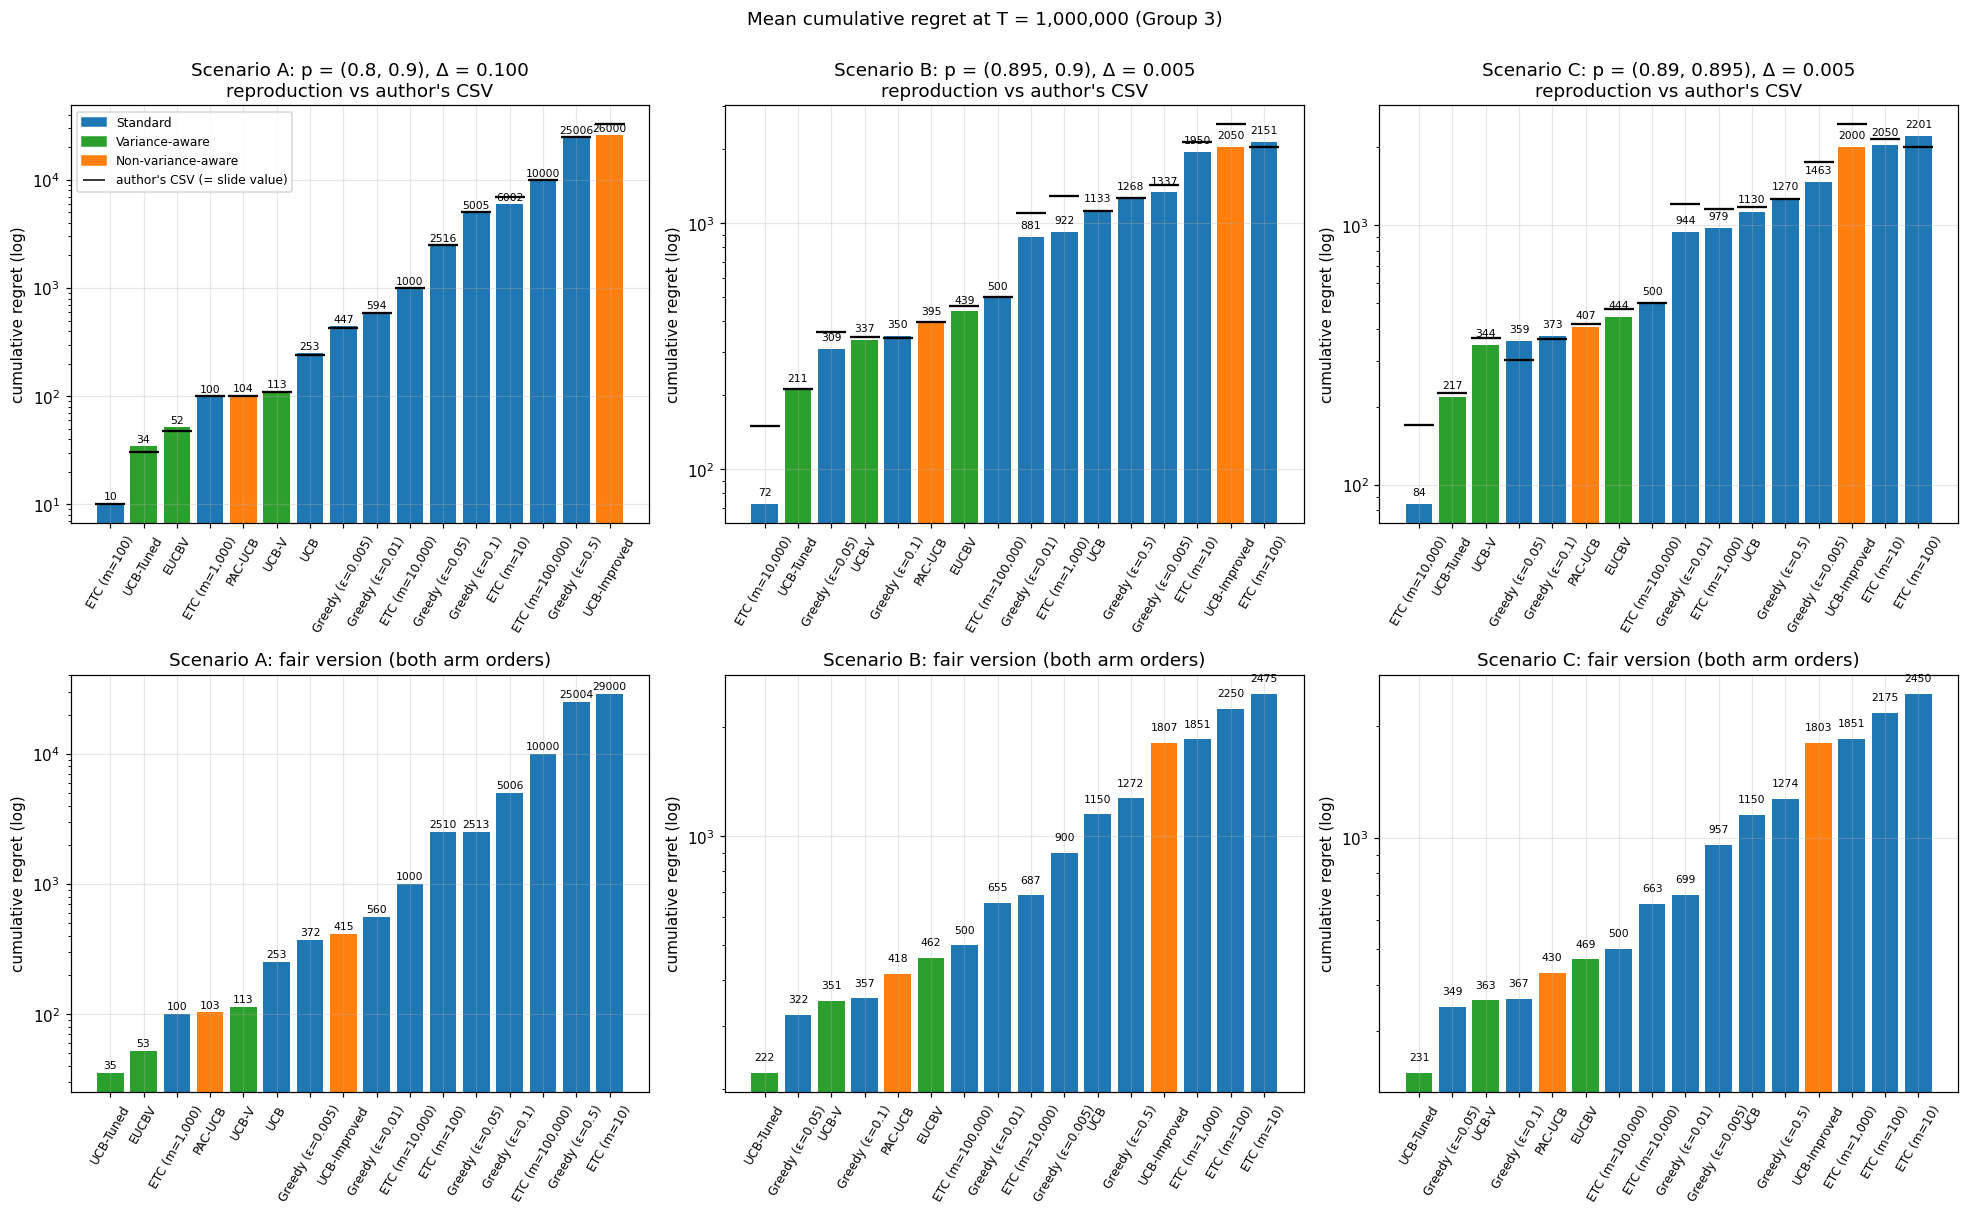

In [13]:
def regret_bars(ax, sub, col, ticks=None):
    sub = sub.sort_values(col)
    bars = ax.bar(sub.algorithm, sub[col], color=[CAT_COLORS[c] for c in sub.category])
    if ticks is not None:
        ax.scatter(sub.algorithm, sub[ticks], marker="_", s=400, color="black", zorder=3)
    for b, v in zip(bars, sub[col]):
        ax.text(b.get_x() + b.get_width() / 2, v * 1.08, f"{v:.0f}", ha="center", fontsize=7)
    ax.set_yscale("log")
    ax.tick_params(axis="x", rotation=60, labelsize=8)

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for j, s in enumerate(SCENARIOS):
    sub = df[df.scenario == s]
    p1, p2 = SCENARIOS[s]
    regret_bars(axes[0, j], sub, "reproduction", ticks="author_csv")
    axes[0, j].set(title=f"Scenario {s}: p = ({p1}, {p2}), Δ = {abs(p2 - p1):.3f}\nreproduction vs author's CSV",
                   ylabel="cumulative regret (log)")
    regret_bars(axes[1, j], sub, "mean_regret")
    axes[1, j].set(title=f"Scenario {s}: fair version (both arm orders)", ylabel="cumulative regret (log)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CAT_COLORS.values()]
handles.append(plt.Line2D([], [], color="black", marker="_", ls="", markersize=15))
axes[0, 0].legend(handles, list(CAT_COLORS) + ["author's CSV (= slide value)"], fontsize=8)
plt.suptitle(f"Mean cumulative regret at T = {T:,} (Group 3)", y=1.0)
plt.tight_layout()
plt.savefig("figures/scenarios_regret.png", bbox_inches="tight")
plt.show()

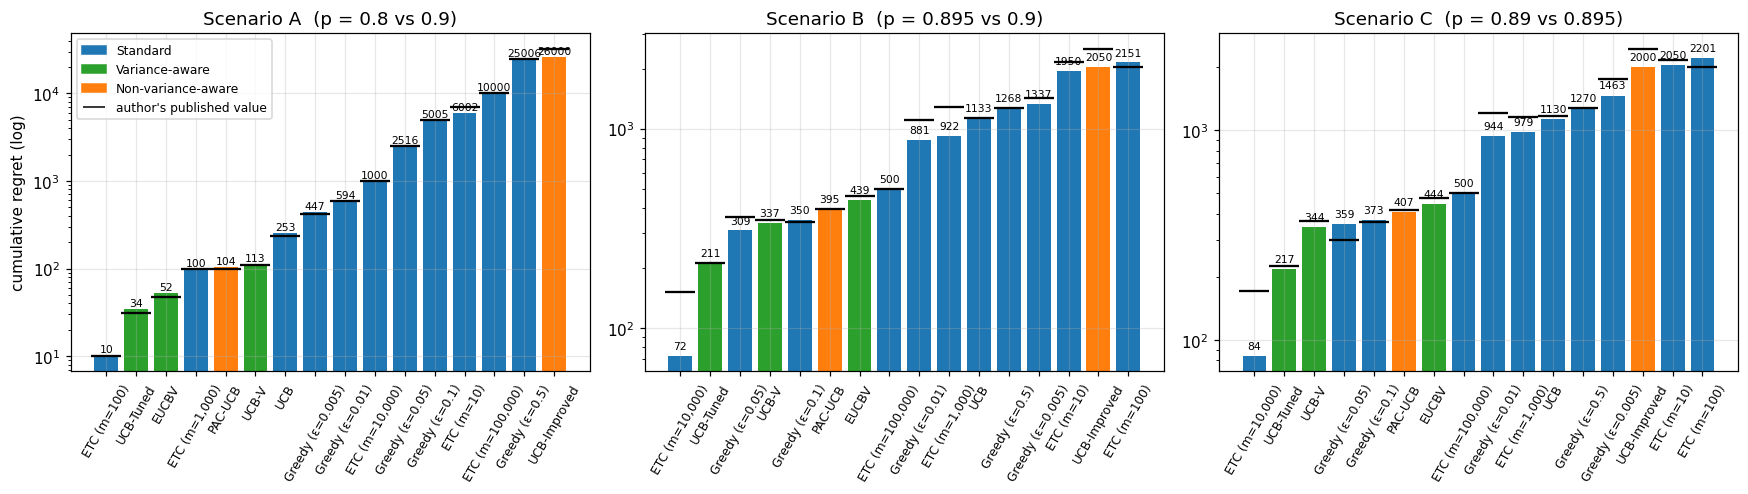

In [14]:
# compact version of the top row for the slides (slide "Critical Reflection 3")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, s in zip(axes, SCENARIOS):
    sub = df[df.scenario == s]
    p1, p2 = SCENARIOS[s]
    regret_bars(ax, sub, "reproduction", ticks="author_csv")
    ax.set(title=f"Scenario {s}  (p = {p1} vs {p2})", ylabel="cumulative regret (log)" if s == "A" else "")
axes[0].legend(handles, ["Standard", "Variance-aware", "Non-variance-aware", "author's published value"], fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig("figures/reproduction_vs_author.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.4 Regret over time and risk (slide 12 metrics)
Left: regret curves for the key algorithms in Scenario C (log–log). UCB-family regret grows like log t, while ETC is linear
during exploration and then flat. Right: per-run regret distribution in Scenario C. Two algorithms with similar mean regret
can differ a lot in spread, which is why the paper also reports risk (VaR).

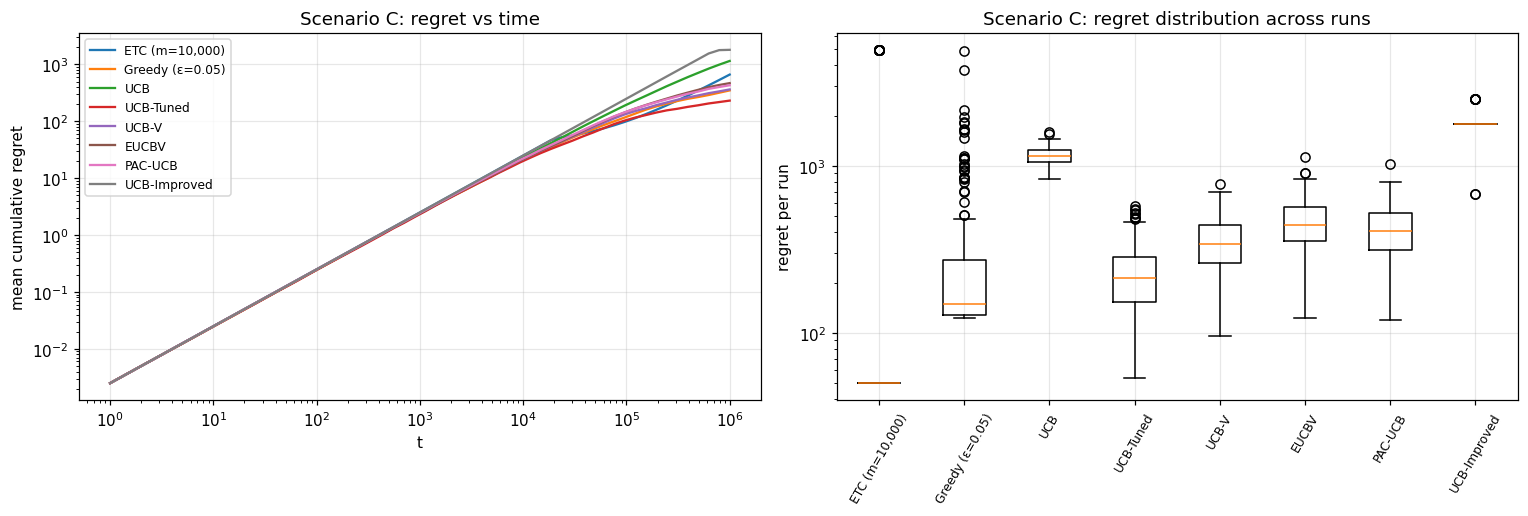

In [15]:
key = ["ETC (m=10,000)", "Greedy (ε=0.05)", "UCB", "UCB-Tuned", "UCB-V", "EUCBV", "PAC-UCB", "UCB-Improved"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for lab in key:
    r = RESULTS[("C", lab)]
    ax[0].plot(r["ckpts"], r["curves"].mean(0), label=lab)
ax[0].set(xscale="log", yscale="log", xlabel="t", ylabel="mean cumulative regret", title="Scenario C: regret vs time")
ax[0].legend(fontsize=8)
ax[1].boxplot([RESULTS[("C", lab)]["regret"] for lab in key], showfliers=True)
ax[1].set_xticks(range(1, len(key) + 1), key)
ax[1].set(yscale="log", ylabel="regret per run", title="Scenario C: regret distribution across runs")
ax[1].tick_params(axis="x", rotation=60, labelsize=8)
plt.tight_layout()
plt.savefig("figures/scenarioC_curves_risk.png", bbox_inches="tight")
plt.show()

### 5.5 Evidence for the UCB-Improved finding
Per-run final regret from the author's own file `UCB-Improved/delta_1/results_800_900.csv`, next to our author-variant
and textbook runs. With a correct phase schedule, phase 0 alone pulls each arm ⌈2 ln T⌉ = 28 times, so regret can never be
below 28 × 0.1 = 2.8. The author's runs ending with regret 0.1–0.3 show that each arm was pulled only once or twice before elimination.

In [16]:
runs_author = author_csv("UCB-Improved", "results_800_900.csv")
final = runs_author.loc[runs_author.Timestep == runs_author.Timestep.max(), "Total Regret"]
bins = [-1, 2.8, 1000, 1e9]
names = ["< 2.8 (impossible if correct)", "2.8 – 1,000", "> 1,000 (wrong arm kept)"]
pd.DataFrame({
    "author's CSV": pd.cut(final, bins, labels=names).value_counts().reindex(names),
    "our author variant": pd.cut(pd.Series(REPRO[("A", "UCB-Improved")]["regret"]), bins, labels=names).value_counts().reindex(names),
    "our textbook version": pd.cut(pd.Series(RESULTS[("A", "UCB-Improved")]["regret"]), bins, labels=names).value_counts().reindex(names),
}).rename_axis("final regret, Scenario A")

,author's CSV,our author variant,our textbook version
"final regret, Scenario A",,,
< 2.8 (impossible if correct),66,70,0
"2.8 – 1,000",0,4,200
"> 1,000 (wrong arm kept)",34,26,0


## 6. Tuning sensitivity

Slide 20: the best ETC setting moves from m = 100 (Scenario A) to m = 10,000 (B, C), a 100× change that cannot be
chosen without knowing the gap in advance. ε-Greedy shows the same U-shape. The headline ranking therefore partly
compares **tuning budgets** rather than algorithms.

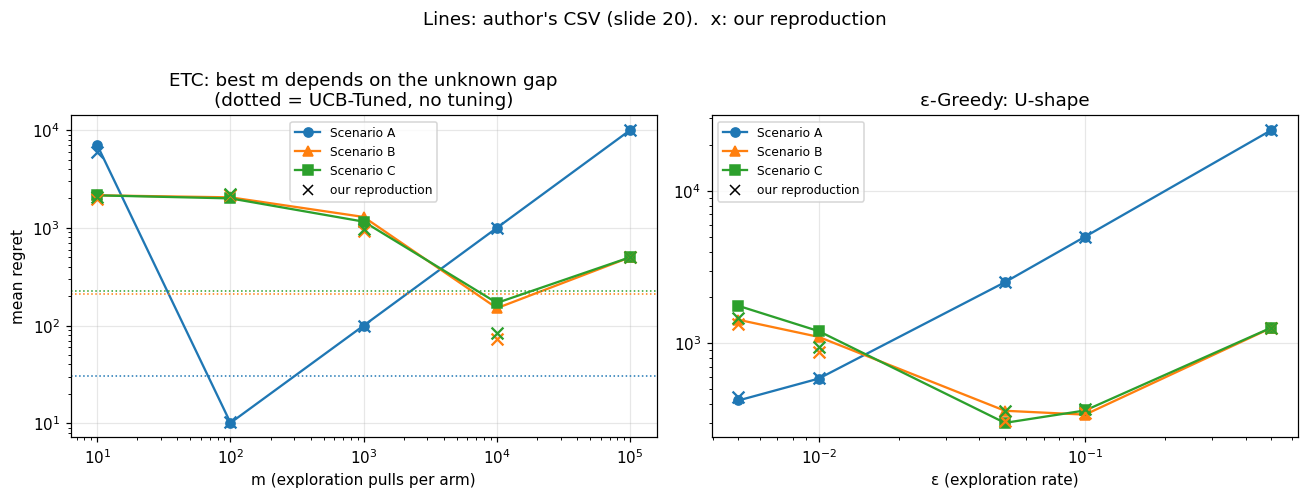

,scenario,algorithm,author_csv,reproduction
1,A,ETC (m=100),10.10,10.33
19,B,"ETC (m=10,000)",150.66,72.36
35,C,"ETC (m=10,000)",170.53,84.28


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
ms = [10, 100, 1_000, 10_000, 100_000]
es = [0.005, 0.01, 0.05, 0.1, 0.5]
for s, mk in zip(SCENARIOS, "o^s"):
    sub = df[df.scenario == s].set_index("algorithm")
    l, = ax[0].plot(ms, [sub.loc[f"ETC (m={m:,})", "author_csv"] for m in ms], marker=mk, label=f"Scenario {s}")
    ax[0].scatter(ms, [sub.loc[f"ETC (m={m:,})", "reproduction"] for m in ms], marker="x", color=l.get_color(), s=60, zorder=3)
    ax[0].axhline(sub.loc["UCB-Tuned", "author_csv"], ls=":", lw=1, color=l.get_color())
    l, = ax[1].plot(es, [sub.loc[f"Greedy (ε={e})", "author_csv"] for e in es], marker=mk, label=f"Scenario {s}")
    ax[1].scatter(es, [sub.loc[f"Greedy (ε={e})", "reproduction"] for e in es], marker="x", color=l.get_color(), s=60, zorder=3)
ax[0].set(xscale="log", yscale="log", xlabel="m (exploration pulls per arm)", ylabel="mean regret",
          title="ETC: best m depends on the unknown gap\n(dotted = UCB-Tuned, no tuning)")
ax[1].set(xscale="log", yscale="log", xlabel="ε (exploration rate)", title="ε-Greedy: U-shape")
for a_ in ax:
    a_.plot([], [], "kx", label="our reproduction")
    a_.legend(fontsize=8)
plt.suptitle("Lines: author's CSV (slide 20).  x: our reproduction", y=1.02)
plt.tight_layout()
plt.savefig("figures/tuning_sensitivity.png", bbox_inches="tight")
plt.show()

best = df.loc[df[df.algorithm.str.startswith("ETC")].groupby("scenario").author_csv.idxmin()]
best[["scenario", "algorithm", "author_csv", "reproduction"]].round(2)

### 6.1 Why ETC's mean regret is fragile
With a true commit, ETC's outcome is **bimodal**. If it commits to the right arm, regret is exactly m·Δ. If it commits
to the wrong arm, regret is about Δ·T (100,000 in A, 5,000 in B/C). The mean over 100–200 runs therefore depends on
how many unlucky commits happened to occur. The author's ETC (§2.1) never locks in, so it can recover from many wrong
choices, which is why the paper's ETC numbers are lower. The probability of a wrong commit can be calculated in advance: the difference of the two
exploration means is approximately normal, so P(wrong) ≈ Φ(−Δ·√m / √(p₁q₁ + p₂q₂)).
The table compares this theoretical rate with the rate we observed and with the rate implied by the paper's reported mean,
(paper − m·Δ) / (Δ·(T − 2m)). This is the risk that the paper's VaR metric is meant to expose. It is another reason why
"ETC is best" depends heavily on tuning and on luck.

In [18]:
rows = []
for s, (p1, p2) in SCENARIOS.items():
    gap = abs(p2 - p1)
    for m in ms:
        lab = f"ETC (m={m:,})"
        reg = RESULTS[(s, lab)]["regret"]
        reg_a = REPRO[(s, lab)]["regret"]
        z = gap * math.sqrt(m) / math.sqrt(p1 * (1 - p1) + p2 * (1 - p2))
        paper = PAPER[s].get(lab, np.nan)
        rows.append({"scenario": s, "algorithm": lab, "regret if correct (m·Δ)": m * gap,
                     "wrong % (theory)": 100 * 0.5 * math.erfc(z / math.sqrt(2)),
                     "wrong % (ours, commit)": 100 * np.mean(reg > 1.5 * m * gap + 1e-9),
                     "wrong % (implied by paper)": 100 * (paper - m * gap) / (gap * (T - 2 * m)),
                     "mean (ours, commit)": reg.mean(), "median (ours, commit)": np.median(reg),
                     "mean (ours, author variant)": reg_a.mean(), "paper": paper})
etc_df = pd.DataFrame(rows)
etc_df.to_csv("results/etc_commit_analysis.csv", index=False)
etc_df.round(2)

,scenario,algorithm,regret if correct (m·Δ),wrong % (theory),"wrong % (ours, commit)",wrong % (implied by paper),"mean (ours, commit)","median (ours, commit)","mean (ours, author variant)",paper
0,A,ETC (m=10),1.00,26.35,29.0,NaN,29000.42,1.00,6001.73,NaN
1,A,ETC (m=100),10.00,2.28,2.5,0.00,2509.50,10.00,10.33,10.10
2,A,"ETC (m=1,000)",100.00,0.00,0.0,0.00,100.00,100.00,100.00,100.00
3,A,"ETC (m=10,000)",1000.00,0.00,0.0,0.00,1000.00,1000.00,1000.00,1000.00
4,A,"ETC (m=100,000)",10000.00,0.00,0.0,NaN,10000.00,10000.00,10000.00,NaN
5,B,ETC (m=10),0.05,48.53,49.5,NaN,2475.00,0.05,1950.02,NaN
6,B,ETC (m=100),0.50,45.36,45.0,NaN,2250.05,0.50,2151.17,NaN
7,B,"ETC (m=1,000)",5.00,35.62,37.0,NaN,1851.30,5.00,921.69,NaN
8,B,"ETC (m=10,000)",50.00,12.19,13.0,2.05,687.00,50.00,72.36,150.66
9,B,"ETC (m=100,000)",500.00,0.01,0.0,NaN,500.00,500.00,500.00,NaN


## 7. Extension — decoupling mean and variance

**Our critique (slide 21).** With 0/1 rewards the variance p(1−p) is fixed once p is chosen, so the paper cannot
change the noise level while holding the gap constant.

**Our experiment (slide 23, future work 1).** We keep the means fixed at **0.45 vs 0.50 (Δ = 0.05)** and draw
rewards from a **Beta distribution** with a chosen variance σ². Rewards stay in [0, 1], so every algorithm's assumptions
still hold. If variance-awareness is what helps, UCB1's regret should stay roughly constant as σ² changes, while UCB-Tuned
and UCB-V should improve as σ² decreases.

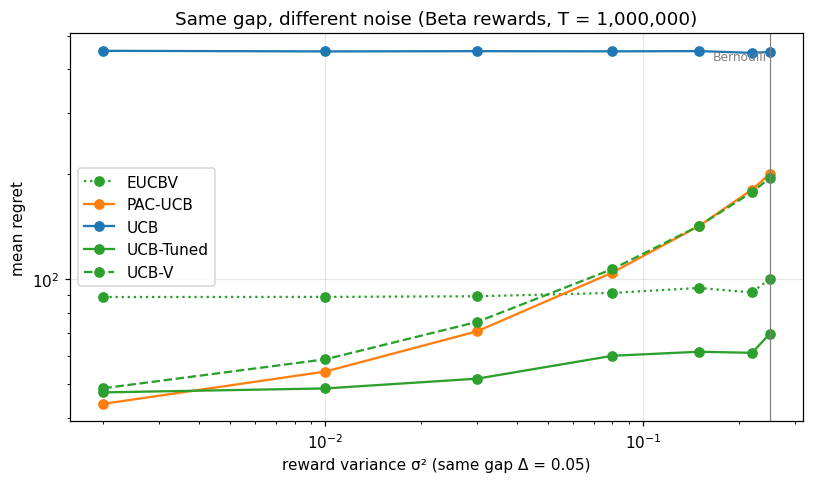

algorithm,EUCBV,PAC-UCB,UCB,UCB-Tuned,UCB-V
sigma2,,,,,
0.002,88.8,43.8,452.1,47.3,48.6
0.010,88.9,54.3,450.4,48.5,58.8
0.030,89.2,70.8,451.1,51.8,75.3
0.080,91.3,104.4,450.6,60.2,106.8
0.150,94.3,142.1,451.3,61.8,142.2
0.220,91.5,180.7,446.1,61.4,177.7
0.250,100.0,200.1,448.8,69.6,194.9


In [19]:
T_EXT = T
RUNS_EXT = RUNS
P_EXT = (0.45, 0.50)
SIGMA2 = [0.002, 0.01, 0.03, 0.08, 0.15, 0.22]                   # < 0.45*0.55 = 0.2475, the Beta limit
EXT_ALGOS = [("UCB", UCB1), ("UCB-Tuned", UCB_TUNED), ("UCB-V", UCB_V), ("EUCBV", EUCBV), ("PAC-UCB", PAC_UCB)]

ext = []
for v in SIGMA2:
    for lab, algo in EXT_ALGOS:
        r = evaluate(algo, 0, P_EXT, T=T_EXT, runs=RUNS_EXT, variances=(v, v))
        ext.append({"sigma2": v, "algorithm": lab, "mean_regret": r["regret"].mean()})
for lab, algo in EXT_ALGOS:                                    # Bernoulli reference point (max variance)
    r = evaluate(algo, 0, P_EXT, T=T_EXT, runs=RUNS_EXT)
    ext.append({"sigma2": 0.25, "algorithm": lab, "mean_regret": r["regret"].mean()})
ext = pd.DataFrame(ext)
ext.to_csv("results/extension_beta_rewards.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
styles = {"UCB": ("#1f77b4", "-"), "UCB-Tuned": ("#2ca02c", "-"), "UCB-V": ("#2ca02c", "--"),
          "EUCBV": ("#2ca02c", ":"), "PAC-UCB": ("#ff7f0e", "-")}
for lab, g in ext.groupby("algorithm"):
    c, ls = styles[lab]
    ax.plot(g.sigma2, g.mean_regret, marker="o", color=c, ls=ls, label=lab)
ax.axvline(0.25, color="grey", lw=0.8)
ax.text(0.245, ax.get_ylim()[1] * 0.9, "Bernoulli", ha="right", fontsize=8, color="grey")
ax.set(xscale="log", yscale="log", xlabel="reward variance σ² (same gap Δ = 0.05)", ylabel="mean regret",
       title=f"Same gap, different noise (Beta rewards, T = {T_EXT:,})")
ax.legend()
plt.tight_layout()
plt.savefig("figures/extension_variance_sweep.png", bbox_inches="tight")
plt.show()
ext.pivot(index="sigma2", columns="algorithm", values="mean_regret").round(1)

**Result** (paper-mode run, T = 10⁶, 200 runs per point):
* **UCB** ignores variance, so its regret is flat (≈ 450) across a 100× change in σ². This is the control.
* **UCB-V** and **PAC-UCB** depend strongly on variance. UCB-V's regret rises about 4× (49 → 195) from the least noisy to the
  noisiest arms at the *same* gap. This is the variance effect the paper wanted to test, now isolated from the gap.
* **UCB-Tuned** has the lowest regret throughout but is only mildly sensitive to variance (47 → 70). Its variance estimate is
  padded by √(2 ln t / n) and capped at ¼.
* **EUCBV** is almost flat (89 → 100) because its confidence radius uses (V̂ + 2), so the constant 2 dominates the variance.

**Takeaway:** "variance-aware" algorithms differ a lot in how much they actually use variance. The paper's Bernoulli design,
where variance changes by only 4 % between B and C, cannot show this.

## 8. Summary and references  *(All)*

In [20]:
summary = (df.loc[df.groupby("scenario").mean_regret.idxmin(), ["scenario", "algorithm", "mean_regret"]]
             .rename(columns={"algorithm": "best overall", "mean_regret": "best regret"}).reset_index(drop=True))
for col, lab in [("UCB", "UCB"), ("UCB-Tuned", "UCB-Tuned")]:
    summary[col] = [df[(df.scenario == s) & (df.algorithm == lab)].mean_regret.item() for s in summary.scenario]
summary["UCB-Tuned / UCB"] = summary["UCB-Tuned"] / summary["UCB"]
print("Files written:", sorted(os.listdir("results")), sorted(os.listdir("figures")))
summary.round(3)

Files written: ['author_published_results.csv', 'etc_commit_analysis.csv', 'extension_beta_rewards.csv', 'main_results.csv', 'per_run_regret.csv'] ['bonus_shrink.png', 'extension_variance_sweep.png', 'reproduction_vs_author.png', 'scenarioC_curves_risk.png', 'scenarios_regret.png', 'tuning_sensitivity.png']


,scenario,best overall,best regret,UCB,UCB-Tuned,UCB-Tuned / UCB
0,A,UCB-Tuned,35.345,253.183,35.345,0.140
1,B,UCB-Tuned,221.913,1150.132,221.913,0.193
2,C,UCB-Tuned,231.021,1149.599,231.021,0.201


**Findings** (paper setting: T = 10⁶)
* **Every number on our slides** matches the author's published CSV files (§5.0). They all come from a single arm order.
* **Our reproduction** (§5.2) uses the author's implementation choices and gives numbers close to the slides for all 16
  settings, apart from random-seed noise. ε-Greedy and ETC with small m have high run-to-run variance, so they differ most.
* **Three implementation issues in the author's code** (§2.1) change the paper's conclusions:
  * ETC never locks in an arm, so it is really "explore, then greedy". With a true commit, ETC is no longer the best algorithm.
  * ε-Greedy depends on arm order and uses an unseeded random generator.
  * UCB-Improved eliminates after one pull per arm, which makes it look much worse than it is (32,500 vs ≈ 415 in Scenario A, §5.5).
* **Fair version** (textbook algorithms, both arm orders): **UCB-Tuned has the lowest mean regret in all three scenarios**.
  It beats plain UCB by about 5× in the micro-gap scenarios B and C. This supports the paper's central claim even more strongly than the paper itself does.
* **Extension (§7):** the paper's B-vs-C comparison changes variance by only 4 %. With Beta rewards we vary the variance
  more than 100× at a fixed gap, which isolates the variance effect that the paper's Bernoulli design cannot.

**References**
1. Wolf (2025). *A Framework for Fair Evaluation of Variance-Aware Bandit Algorithms.* arXiv:2510.27001.
2. Bandit Playground (author's code and published result CSVs), https://github.com/eelisee/bandit_playground/tree/v1.0-SKILL2025
   — algorithms in `src/algorithms/`, constants in `src/config.py`, results in `data/`
3. Auer, P., Cesa-Bianchi, N., Fischer, P. (2002). Finite-time analysis of the multiarmed bandit problem. *Machine Learning* 47. (UCB1, UCB-Tuned)
4. Audibert, J.-Y., Munos, R., Szepesvári, Cs. (2009). Exploration–exploitation tradeoff using variance estimates in multi-armed bandits. *Theoretical Computer Science* 410. (UCB-V, PAC-UCB)
5. Auer, P., Ortner, R. (2010). UCB revisited: Improved regret bounds for the stochastic multi-armed bandit problem. *Periodica Mathematica Hungarica* 61. (UCB-Improved)
6. Mukherjee, S., Naveen, K. P., Sudarsanam, N., Ravindran, B. (2018). Efficient-UCBV: An almost optimal algorithm using variance estimates. *AAAI*. (EUCBV)
7. Lattimore, T., Szepesvári, Cs. (2020). *Bandit Algorithms.* Cambridge University Press. (ETC, regret definitions)
8. Sutton, R. S., Barto, A. G. (2018). *Reinforcement Learning: An Introduction*, 2nd ed. (ε-Greedy)